In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms

from plot_style import C, apply

FIG = Path("figs")
DATA_PATH = FIG / "data" / "heteroclinic_shooting_data.npz"
OUTPUT = FIG / "Fig12.pdf"

apply()

with np.load(DATA_PATH) as data:
    ratios = data["ratios"]
    dmin_to_saddles = data["dmin_to_other_saddles"]
    dmin_to_clusters = data["dmin_to_cluster_attractor"]
    demo_r = float(data["demo_r"])
    demo_t = data["demo_t"]
    demo_to_cluster = data["demo_distance_to_cluster_attractor"]
    demo_to_saddles = data["demo_distance_to_other_saddles"]
    onset_band = data["r_onset_ci"]
    focus_transition = float(data["saddle_focus_transition"])

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )

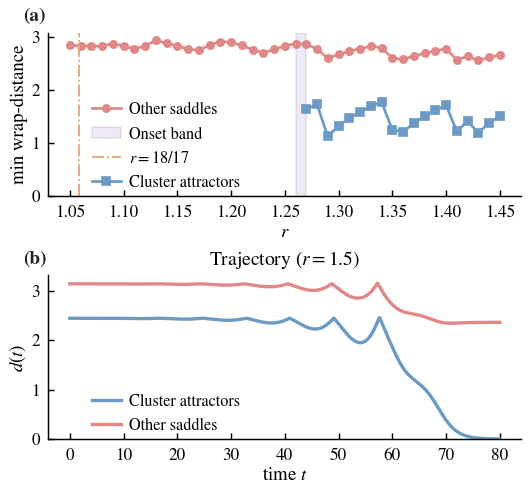

In [3]:
FIGSIZE = (3.45, 3.2)
TICK_FONT_SIZE = 6.9 * 1.2
LABEL_FONT_SIZE = 7.5 * 1.2
TITLE_FONT_SIZE = 7.8 * 1.2
LEGEND_FONT_SIZE = 6.5 * 1.2
PANEL_FONT_SIZE = 7.7 * 1.2
LINE_WIDTH = 1.3
TRAJECTORY_LINE_WIDTH = 1.6
MARKER_SIZE = 3.5

legend_options = dict(
    loc="lower left", bbox_to_anchor=(0.08, 0.0), borderaxespad=0.0,
    fontsize=LEGEND_FONT_SIZE, framealpha=0.0,
    facecolor="none", edgecolor="none",
)

fig, axes = plt.subplots(2, 1, figsize=FIGSIZE, constrained_layout=False)
for axis in axes:
    axis.tick_params(axis="both", direction="in", labelsize=TICK_FONT_SIZE, pad=4.0)
    axis.xaxis.labelpad = 1.4
    axis.yaxis.labelpad = 1.4

vertical_maximum = 1.05 * max(np.nanmax(dmin_to_saddles), np.nanmax(dmin_to_clusters))

axes[0].plot(
    ratios, dmin_to_saddles, "o-", color=C["red"],
    markersize=MARKER_SIZE, linewidth=LINE_WIDTH, label="Other saddles",
)
axes[0].axvspan(
    onset_band[0], onset_band[1], color=C["purple"], alpha=0.18,
    label="Onset band",
)
axes[0].axvline(
    focus_transition, color=C["orange"], linestyle="-.", linewidth=0.9,
    label=r"$r=18/17$",
)
finite_cluster = np.isfinite(dmin_to_clusters)
axes[0].plot(
    ratios[finite_cluster], dmin_to_clusters[finite_cluster], "s-",
    color=C["blue"], markersize=MARKER_SIZE, linewidth=LINE_WIDTH,
    label="Cluster attractors",
)
axes[0].set_xlabel(r"$r$", fontsize=LABEL_FONT_SIZE)
axes[0].set_ylabel("min wrap-distance", fontsize=LABEL_FONT_SIZE)
axes[0].set_ylim(0.0, vertical_maximum)
axes[0].legend(**legend_options)

axes[1].plot(
    demo_t, demo_to_cluster, color=C["blue"],
    linewidth=TRAJECTORY_LINE_WIDTH, label="Cluster attractors",
)
axes[1].plot(
    demo_t, demo_to_saddles, color=C["red"],
    linewidth=TRAJECTORY_LINE_WIDTH, label="Other saddles",
)
axes[1].set_xlabel(r"time $t$", fontsize=LABEL_FONT_SIZE)
axes[1].set_ylabel(r"$d(t)$", fontsize=LABEL_FONT_SIZE)
axes[1].set_title(rf"Trajectory ($r={demo_r:g}$)", fontsize=TITLE_FONT_SIZE, pad=5.0)
axes[1].set_ylim(bottom=0.0)
axes[1].legend(**legend_options)

for panel, axis in enumerate(axes):
    panel_label(axis, f"({chr(97 + panel)})", fontsize=PANEL_FONT_SIZE)

fig.tight_layout(pad=0.10, h_pad=0.45)
fig.savefig(OUTPUT)
plt.show()